# Long-Only Factor Trend Basket - Brazil

An individual investor in Brazil cannot short stocks without a lending account, so the easiest way to use factors is to buy only their long side. This notebook applies the trend index of `05_multi_factor_strategy` to the long leg of six factors and allocates to them in proportion to their trend. All the stocks of the factors held go into a single basket, so a stock held by more than one factor gets a larger weight.

The six factors are five composites of `04_factor_screening` (Value, Profitability, Growth, Leverage and Low Risk) and Momentum. The components of the composites are left out, so that each theme enters once. Three factors of `04_` are also left out: Size, because buying the smallest companies in Brazil carries a large liquidity risk and much information asymmetry; Reversal, which overlaps with Momentum; and the Magic Formula, which is a strategy built from other factors rather than a factor. The long leg of each factor is its top quintile, as in `04_`.

The notebook first applies the same trend index to single stocks, a test that was in `04_factor_screening`, and then to the factors.

For the factors, the study has two stages:
- **Stage 1** uses the daily returns of each factor's long leg and keeps the factor weights fixed during the month. It is an approximation, used for the robustness tests.
- **Stage 2** is the backtest of the single basket, stock by stock, with the engine of the other notebooks. It is also used to measure the concentration of the basket.

The results are in sample and before transaction costs.

In [1]:
# Library imports

import pandas as pd
import numpy as np
import statsmodels.api as sm
import quantstats as qs
from scipy import stats

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

from datetime import date, timedelta
from  bizdays import Calendar, set_option

cal = Calendar.load('ANBIMA')
set_option('mode', 'pandas')
from tqdm import tqdm
import seaborn as sns

### Data and signals

The data, the universe and the z-scores are the same as in `04_factor_screening`; the cells below are copied from it without changes.

In [2]:
# Imports data already collected to make the analysis easier

path = '.'
factors_folder = 'factors'
data_folder = 'data'

companies = pd.read_csv(path + "/" + data_folder + "/" + 'index_composition.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
prices_df = pd.read_csv(path + "/" + data_folder + "/" + 'prices.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
volume = pd.read_csv(path + "/" + data_folder + "/" + 'volume.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
benchmarks = pd.read_csv(path + "/" + data_folder + "/" + 'benchmarks.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
ff_factors = pd.read_csv(path + "/" + data_folder + "/" + 'ff_factors.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Market factors
market_value = pd.read_csv(path + "/" + data_folder + "/" + 'relative_market_value.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
momentum = pd.read_csv(path + "/" + factors_folder + "/" + 'momentum.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
reversal = pd.read_csv(path + "/" + factors_folder + "/" + 'reversal.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
volatility = pd.read_csv(path + "/" + factors_folder + "/" + 'volatility.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
bab = pd.read_csv(path + "/" + factors_folder + "/" + 'bab.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
ivol = pd.read_csv(path + "/" + factors_folder + "/" + 'ivol.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Profitability factors
roe = pd.read_csv(path + "/" + factors_folder + "/" + 'roe.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
roa = pd.read_csv(path + "/" + factors_folder + "/" + 'roa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
gpoa = pd.read_csv(path + "/" + factors_folder + "/" + 'gpoa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
cfoa = pd.read_csv(path + "/" + factors_folder + "/" + 'cfoa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
acc = pd.read_csv(path + "/" + factors_folder + "/" + 'acc.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Growth factors
g_revenue = pd.read_csv(path + "/" + factors_folder + "/" + 'g_revenue.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
g_ebitda = pd.read_csv(path + "/" + factors_folder + "/" + 'g_ebitda.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
g_earnings = pd.read_csv(path + "/" + factors_folder + "/" + 'g_earnings.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
investments = pd.read_csv(path + "/" + factors_folder + "/" + 'investments.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Leverage factors
debt_to_assets = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_to_assets.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_to_ebitda = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_to_ebitda.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_to_equity = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_to_equity.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
liab_to_equity = pd.read_csv(path + "/" + factors_folder + "/" + 'liab_to_equity.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Value factors
earnings_yield = pd.read_csv(path + "/" + factors_folder + "/" + 'earnings_yield.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
book_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'book_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
sales_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'sales_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
fcf_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'fcf_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
ebitda_ev = pd.read_csv(path + "/" + factors_folder + "/" + 'ebitda_ev.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Magic Formula
roc_mf = pd.read_csv(path + "/" + factors_folder + "/" + 'roc_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
earnings_yield_mf = pd.read_csv(path + "/" + factors_folder + "/" + 'earnings_yield_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_ebit_mf = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_ebit_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Index rebalancing dates
rebalance_dates = sorted(companies.index.unique())

# Backtest dates
ini_date = cal.preceding(rebalance_dates[0] - timedelta(days = 1)).date()
end_date = date.today()
nefin = pd.read_csv(path + "/" + data_folder + "/" + 'nefin_factors.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

In [3]:
ticker_codes = [tick[0:4] for tick in sorted(companies['Ticker'].unique())]
repeated_tickers = [tick for tick in ticker_codes if ticker_codes.count(tick) > 1]
repeated_tickers = list(dict.fromkeys(repeated_tickers))

vol_median = volume.ffill(limit=1).rolling(42).median()

for tick in repeated_tickers:
    rep = volume.columns[volume.columns.str.contains(tick)]
    ticker_filter = vol_median[rep].apply(lambda r: np.where(r == r.max(), r, np.nan), axis = 1)
    vol_median[rep] = pd.DataFrame(ticker_filter.tolist(), columns = rep, index = vol_median.index)

In [4]:
# Creates a matrix with the investable companies on each rebalancing date, showing the new index composition
investable = companies.loc[companies['Index'].isin(['SMLL', 'MLCX'])].pivot_table(index = 'Date', columns = 'Ticker', values = 'Weight')

# Multiplies by 0 and adds 1 to turn all values into 1, indicating that the company is investable
investable = investable.mul(0).add(1)

# Reindexes the table so that all backtest dates are present
investable = investable.reindex(market_value.index, method='ffill')
investable.loc[:date(2009,1,2)] = investable.loc[date(2009,1,5):date(2009,1,5)].values

# Creates a dataframe showing whether the stock had a price on the day, avoiding companies that left the market
has_price = prices_df.apply(lambda col: np.where((col.isna()) | (col <= 0), np.nan, 1)).loc[investable.index]

# Creates a dataframe to filter companies with low liquidity, avoiding companies whose prices are a problem to trade
volume_filter = vol_median.apply(lambda col: np.where(col > 1000, 1, np.nan))

In [5]:
# Sector filter for the Magic Formula
# Excludes Financials and Utilities companies
mf_filter = companies.loc[~companies['Sector'].isin(['Financeiro', 'Financeiro e Outros', 'Utilidade Pública'])].pivot_table(index = 'Date', columns = 'Ticker', values = 'Weight')

# Multiplies by 0 and adds 1 to turn all values into 1, indicating that the company is investable
mf_filter = mf_filter.mul(0).add(1)

# Reindexes the table so that all backtest dates are present
mf_filter = mf_filter.reindex(market_value.index, method='ffill')
mf_filter.loc[:date(2009,1,2)] = mf_filter.loc[date(2009,1,5):date(2009,1,5)].values

In [6]:
# Multiplies the indicators dataframe by investable and has_price to filter all dates at once
# Values multiplied by NaN become NaN, leaving only the values of companies that are investable on the date and have a price
roe = roe * investable * has_price * volume_filter
roa = roa * investable * has_price * volume_filter
gpoa = gpoa * investable * has_price * volume_filter
cfoa = cfoa * investable * has_price * volume_filter
acc = acc * investable * has_price * volume_filter

g_revenue = g_revenue * investable * has_price * volume_filter
g_ebitda = g_ebitda * investable * has_price * volume_filter
g_earnings = g_earnings * investable * has_price * volume_filter
investments = investments * investable * has_price * volume_filter

debt_to_assets = debt_to_assets * investable * has_price * volume_filter
debt_to_ebitda = debt_to_ebitda * investable * has_price * volume_filter
debt_to_equity = debt_to_equity * investable * has_price * volume_filter
liab_to_equity = liab_to_equity * investable * has_price * volume_filter

earnings_yield = earnings_yield * investable * has_price * volume_filter
book_to_price = book_to_price * investable * has_price * volume_filter
sales_to_price = sales_to_price * investable * has_price * volume_filter
fcf_to_price = fcf_to_price * investable * has_price * volume_filter
ebitda_ev = ebitda_ev * investable * has_price * volume_filter

momentum = momentum * investable * has_price * volume_filter
reversal = reversal * investable * has_price * volume_filter
volatility = volatility * investable * has_price * volume_filter
market_value = market_value * investable * has_price * volume_filter
bab = bab * investable * has_price * volume_filter
ivol = ivol * investable * has_price * volume_filter

roc_mf = roc_mf * investable * has_price * volume_filter * mf_filter
earnings_yield_mf = earnings_yield_mf * investable * has_price * volume_filter * mf_filter
debt_ebit_mf = debt_ebit_mf * investable * has_price * volume_filter * mf_filter

# Reindexes the dataframes so that all backtest dates are present
roe = roe.loc[volume.index]
roa = roa.loc[volume.index]
gpoa = gpoa.loc[volume.index]
cfoa = cfoa.loc[volume.index]
acc = acc.loc[volume.index]

g_revenue = g_revenue.loc[volume.index]
g_ebitda = g_ebitda.loc[volume.index]
g_earnings = g_earnings.loc[volume.index]
investments = investments.loc[volume.index]

debt_to_assets = debt_to_assets.loc[volume.index]
debt_to_ebitda = debt_to_ebitda.loc[volume.index]
debt_to_equity = debt_to_equity.loc[volume.index]
liab_to_equity = liab_to_equity.loc[volume.index]

earnings_yield = earnings_yield.loc[volume.index]
book_to_price = book_to_price.loc[volume.index]
sales_to_price = sales_to_price.loc[volume.index]
fcf_to_price = fcf_to_price.loc[volume.index]
ebitda_ev = ebitda_ev.loc[volume.index]

momentum = momentum.loc[volume.index]
reversal = reversal.loc[volume.index]
volatility = volatility.loc[volume.index]
market_value = market_value.loc[volume.index]
bab = bab.loc[volume.index]
ivol = ivol.loc[volume.index]

roc_mf = roc_mf.loc[volume.index]
earnings_yield_mf = earnings_yield_mf.loc[volume.index]
debt_ebit_mf = debt_ebit_mf.loc[volume.index]

In [7]:
# Calculates z-scores using numpy
z_roe = stats.zscore(roe.values, axis=1, nan_policy='omit')
z_roa = stats.zscore(roa.values, axis=1, nan_policy='omit')
z_gpoa = stats.zscore(gpoa.values, axis=1, nan_policy='omit')
z_cfoa = stats.zscore(cfoa.values, axis=1, nan_policy='omit')
z_acc = stats.zscore(acc.values, axis=1, nan_policy='omit')
z_g_revenue = stats.zscore(g_revenue.values, axis=1, nan_policy='omit')
z_g_ebitda = stats.zscore(g_ebitda.values, axis=1, nan_policy='omit')
z_g_earnings = stats.zscore(g_earnings.values, axis=1, nan_policy='omit')
z_investments = stats.zscore(investments.values, axis=1, nan_policy='omit')
z_debt_to_assets = stats.zscore(debt_to_assets.values, axis=1, nan_policy='omit')
z_debt_to_ebitda = stats.zscore(debt_to_ebitda.values, axis=1, nan_policy='omit')
z_debt_to_equity = stats.zscore(debt_to_equity.values, axis=1, nan_policy='omit')
z_liab_to_equity = stats.zscore(liab_to_equity.values, axis=1, nan_policy='omit')
z_ey = stats.zscore(earnings_yield.values, axis=1, nan_policy='omit')
z_bp = stats.zscore(book_to_price.values, axis=1, nan_policy='omit')
z_sales = stats.zscore(sales_to_price.values, axis=1, nan_policy='omit')
z_fcf = stats.zscore(fcf_to_price.values, axis=1, nan_policy='omit')
z_ev = stats.zscore(ebitda_ev.values, axis=1, nan_policy='omit')
z_mom = stats.zscore(momentum.values, axis=1, nan_policy='omit')
z_rev = stats.zscore(reversal.values, axis=1, nan_policy='omit')
z_vol = stats.zscore(volatility.values, axis=1, nan_policy='omit')
z_size = stats.zscore(market_value.values, axis=1, nan_policy='omit')
z_bab = stats.zscore(bab.values, axis=1, nan_policy='omit')
z_ivol = stats.zscore(ivol.values, axis=1, nan_policy='omit')
z_roc_mf = stats.zscore(roc_mf.values, axis=1, nan_policy='omit')
z_ey_mf = stats.zscore(earnings_yield_mf.values, axis=1, nan_policy='omit')
z_de_mf = stats.zscore(debt_ebit_mf.values, axis=1, nan_policy='omit')

# Replaces values outside the [-2, 2] range with NaN
z_roe = np.where((z_roe >= -2) & (z_roe <= 2), z_roe, np.nan)
z_roa = np.where((z_roa >= -2) & (z_roa <= 2), z_roa, np.nan)
z_gpoa = np.where((z_gpoa >= -2) & (z_gpoa <= 2), z_gpoa, np.nan)
z_cfoa = np.where((z_cfoa >= -2) & (z_cfoa <= 2), z_cfoa, np.nan)
z_acc = np.where((z_acc >= -2) & (z_acc <= 2), z_acc, np.nan)
z_g_revenue = np.where((z_g_revenue >= -2) & (z_g_revenue <= 2), z_g_revenue, np.nan)
z_g_ebitda = np.where((z_g_ebitda >= -2) & (z_g_ebitda <= 2), z_g_ebitda, np.nan)
z_g_earnings = np.where((z_g_earnings >= -2) & (z_g_earnings <= 2), z_g_earnings, np.nan)
z_investments = np.where((z_investments >= -2) & (z_investments <= 2), z_investments, np.nan)
z_debt_to_assets = np.where((z_debt_to_assets >= -2) & (z_debt_to_assets <= 2), z_debt_to_assets, np.nan)
z_debt_to_ebitda = np.where((z_debt_to_ebitda >= -2) & (z_debt_to_ebitda <= 2), z_debt_to_ebitda, np.nan)
z_debt_to_equity = np.where((z_debt_to_equity >= -2) & (z_debt_to_equity <= 2), z_debt_to_equity, np.nan)
z_liab_to_equity = np.where((z_liab_to_equity >= -2) & (z_liab_to_equity <= 2), z_liab_to_equity, np.nan)
z_ey = np.where((z_ey >= -2) & (z_ey <= 2), z_ey, np.nan)
z_bp = np.where((z_bp >= -2) & (z_bp <= 2), z_bp, np.nan)
z_sales = np.where((z_sales >= -2) & (z_sales <= 2), z_sales, np.nan)
z_fcf = np.where((z_fcf >= -2) & (z_fcf <= 2), z_fcf, np.nan)
z_ev = np.where((z_ev >= -2) & (z_ev <= 2), z_ev, np.nan)
z_roc_mf = np.where((z_roc_mf >= -2) & (z_roc_mf <= 2), z_roc_mf, np.nan)
z_ey_mf = np.where((z_ey_mf >= -2) & (z_ey_mf <= 2), z_ey_mf, np.nan)
z_de_mf = np.where((z_de_mf >= -2) & (z_de_mf <= 2), z_de_mf, np.nan)

# Converts the result back to a DataFrame, preserving index and columns
z_roe = pd.DataFrame(z_roe, columns=roe.columns, index=roe.index)
z_roa = pd.DataFrame(z_roa, columns=roa.columns, index=roa.index)
z_gpoa = pd.DataFrame(z_gpoa, columns=gpoa.columns, index=gpoa.index)
z_cfoa = pd.DataFrame(z_cfoa, columns=cfoa.columns, index=cfoa.index)
z_acc = pd.DataFrame(z_acc, columns=acc.columns, index=acc.index)
z_g_revenue = pd.DataFrame(z_g_revenue, columns=g_revenue.columns, index=g_revenue.index)
z_g_ebitda = pd.DataFrame(z_g_ebitda, columns=g_ebitda.columns, index=g_ebitda.index)
z_g_earnings = pd.DataFrame(z_g_earnings, columns=g_earnings.columns, index=g_earnings.index)
z_investments = pd.DataFrame(z_investments, columns=investments.columns, index=investments.index)
z_debt_to_assets = pd.DataFrame(z_debt_to_assets, columns=debt_to_assets.columns, index=debt_to_assets.index)
z_debt_to_ebitda = pd.DataFrame(z_debt_to_ebitda, columns=debt_to_ebitda.columns, index=debt_to_ebitda.index)
z_debt_to_equity = pd.DataFrame(z_debt_to_equity, columns=debt_to_equity.columns, index=debt_to_equity.index)
z_liab_to_equity = pd.DataFrame(z_liab_to_equity, columns=liab_to_equity.columns, index=liab_to_equity.index)
z_ey = pd.DataFrame(z_ey, columns=earnings_yield.columns, index=earnings_yield.index)
z_bp = pd.DataFrame(z_bp, columns=book_to_price.columns, index=book_to_price.index)
z_sales = pd.DataFrame(z_sales, columns=sales_to_price.columns, index=sales_to_price.index)
z_fcf = pd.DataFrame(z_fcf, columns=fcf_to_price.columns, index=fcf_to_price.index)
z_ev = pd.DataFrame(z_ev, columns=ebitda_ev.columns, index=ebitda_ev.index)
z_mom = pd.DataFrame(z_mom, columns=momentum.columns, index=momentum.index)
z_rev = pd.DataFrame(z_rev, columns=reversal.columns, index=reversal.index)
z_vol = pd.DataFrame(z_vol, columns=volatility.columns, index=volatility.index)
z_size = pd.DataFrame(z_size, columns=market_value.columns, index=market_value.index)
z_bab = pd.DataFrame(z_bab, columns=bab.columns, index=bab.index)
z_ivol = pd.DataFrame(z_ivol, columns=ivol.columns, index=ivol.index)
z_roc_mf = pd.DataFrame(z_roc_mf, columns=roc_mf.columns, index=roc_mf.index)
z_ey_mf = pd.DataFrame(z_ey_mf, columns=earnings_yield_mf.columns, index=earnings_yield_mf.index)
z_de_mf = pd.DataFrame(z_de_mf, columns=debt_ebit_mf.columns, index=debt_ebit_mf.index)

# Calculates the aggregate scores
z_profitability = z_roe + z_gpoa + z_cfoa + z_acc + z_roa
z_growth = z_g_revenue + z_g_ebitda + z_g_earnings
z_safety = -z_debt_to_assets - z_debt_to_ebitda - z_liab_to_equity
z_lowrisk = z_bab - z_vol - z_ivol
z_value = z_ev + z_ey + z_fcf + z_bp + z_sales
z_mf = -stats.zscore(roc_mf.rank(axis=1, ascending=False) + earnings_yield_mf.rank(axis=1, ascending=False) + debt_ebit_mf.rank(axis=1, ascending=True), axis=1, nan_policy='omit')

# Converts the final result to a DataFrame
z_mf = pd.DataFrame(z_mf, columns=roc_mf.columns, index=roc_mf.index)

In [8]:
from brfactors.selection import get_quintiles, get_longshort_decile, get_longshort_amount
from brfactors.backtest import backtest_quintiles, backtest_longshort
from brfactors.trend import trend_signal

In [9]:
# Value Factors
value = {'Book to Price' : z_bp, 'EV to Ebitda' : z_ev, 'Sales to Price' : z_sales, 'Free Cash Flow to Price' : z_fcf, 'Earnings Yield' : z_ey, 'Value Composite' : z_value}
profitability = {'Return on Equity' : z_roe, 'Return on Assets' : z_roa, 'Gross Profit over Assets' : z_gpoa, 'Cashflow over Assets' : z_cfoa, 'Accruals' : z_acc, 'Profitability Composite' : z_profitability}
growth = {'Revenue Growth' : z_g_revenue, 'Ebitda Growth' : z_g_ebitda, 'Earnings Growth' : z_g_earnings, 'Growth Composite' : z_growth, "Investments": z_investments}
leverage = {'Debt to Assets' : -z_debt_to_assets, 'Debt to Ebitda' : -z_debt_to_ebitda, 'Debt to Equity' : -z_debt_to_equity, 'Liabilities to Equity' : -z_liab_to_equity, 'Leverage Composite' : z_safety}
market = {'Momentum' : z_mom, 'Reversal' : z_rev, 'Low Vol' : -z_vol, 'Size' : -z_size, 'BAB' : z_bab, 'IVOL' : -z_ivol, 'Low Risk Composite' : z_lowrisk}
magic_formula = {'Return on Capital' : z_roc_mf, 'Earnings Yield MF' : z_ey_mf, 'Debt to Ebit MF' : -z_de_mf, 'Magic Formula Composite' : z_mf}

# List with all factors
factors_dict = dict()
factors_dict.update(value)
factors_dict.update(profitability)
factors_dict.update(growth)
factors_dict.update(leverage)
factors_dict.update(market)
factors_dict.update(magic_formula)

# The six factors of the strategy: five composites and Momentum
trend_factors = ['Value Composite', 'Profitability Composite', 'Growth Composite', 'Leverage Composite', 'Low Risk Composite', 'Momentum']

# Trend on single stocks

The trend index is first applied to the price of each stock in the investable universe. Every day, the stocks are sorted into quintiles of their trend, and a second portfolio holds the 20 stocks with the strongest trend; both are rebalanced daily with equal weights. These cells come from `04_factor_screening`, with two variables renamed so that they do not overwrite the trend function and the monthly rebalancing dates used below.

In [10]:
# Stock trend following
# Cumulative return of the strategy
# factors_quintiles_returns_df = pd.DataFrame({k: v['Daily return'] for k,v in zip(factors_ls_returns.keys(), factors_ls_returns.values())}).replace(0, np.nan)
ret_strategy = prices_df

# Exponential moving average (EWMA)
ewm_mean_5d = ret_strategy.ewm(span = 10).mean()
ewm_mean_21d = ret_strategy.ewm(span = 21).mean()
ewm_mean_63d = ret_strategy.ewm(span = 63).mean()
ewm_mean_126d = ret_strategy.ewm(span = 126).mean()
ewm_mean_252d = ret_strategy.ewm(span = 252).mean()

# Calculation of the spreads between the moving averages
spread_5d_21d = ewm_mean_5d - ewm_mean_21d
spread_21d_63d = ewm_mean_21d - ewm_mean_63d
spread_63d_126d = ewm_mean_63d - ewm_mean_126d
spread_126d_252d = ewm_mean_126d - ewm_mean_252d

# Normalization of the spreads by the standard deviation
norm_spread_5d_21d = spread_5d_21d / spread_5d_21d.rolling(252).std()
norm_spread_21d_63d = spread_21d_63d / spread_21d_63d.rolling(252).std()
norm_spread_63d_126d = spread_63d_126d / spread_63d_126d.rolling(252).std()
norm_spread_126d_252d = spread_126d_252d / spread_126d_252d.rolling(252).std()

# Trend signal calculation with the hyperbolic tangent
signal_5d_21d = np.tanh(norm_spread_5d_21d)
signal_21d_63d = np.tanh(norm_spread_21d_63d)
signal_63d_126d = np.tanh(norm_spread_63d_126d)
signal_126d_252d = np.tanh(norm_spread_126d_252d)

# Adjusted trend signal calculation: average of the signals
stock_trend_signal = (signal_5d_21d + signal_21d_63d + signal_63d_126d + signal_126d_252d) / 4
stock_trend_signal = stock_trend_signal.mul(investable * has_price * volume_filter)

In [11]:
# # List of dates by weekday for weekly rebalancing
# def get_weekday_list(week_day, year, month):
#     # Creates a list of dates from the weekday given in the parameter, adding seven days up to a limit date
#     first_date = cal.getdate(week_day, year, month)
#     date_list = [first_date]

#     while (date_list[-1] + timedelta(7)).date() < date.today():
#         date_list.append(date_list[-1] + timedelta(7))

#     return date_list

# daily_rebalance_dates = [cal.following(dt) for dt in get_weekday_list('first mon', 2009, 1)] # All Mondays that are business days from 2009 to May/2025

# daily_rebalance_dates = [date(year, month, 1) for year in range(2009, 2027) for month in range(1,13, 1)]
# daily_rebalance_dates = [cal.following(ref_date) for ref_date in daily_rebalance_dates if ref_date < date.today()]

daily_rebalance_dates = prices_df.loc[date(2009,1,1):].index.tolist()

In [12]:
# Creates a dictionary with the 5 quintiles and their companies
quintiles = {'{:.0f}Q'.format((n+2)/2): get_quintiles(n/10, (n+2)/10, stock_trend_signal) for n in range(0,10, 2)}
# Calculates the daily return for all quintiles
quintiles_returns = {k: backtest_quintiles(prices_df, v, daily_rebalance_dates, market_value) for k,v in zip(quintiles.keys(), quintiles.values())}

bottom_20, top_20 = get_longshort_amount(20, stock_trend_signal)
top_returns = backtest_quintiles(prices_df, top_20, daily_rebalance_dates, market_value)

quintiles_returns.update({'Top 20': top_returns})

Annualized return - Trend Follow:
 1Q        0.045880
2Q        0.103249
3Q        0.130182
4Q        0.133265
5Q        0.186719
Top 20    0.200383
dtype: float64
Annualized volatility - Trend Follow:
 1Q        0.286796
2Q        0.266169
3Q        0.243014
4Q        0.224519
5Q        0.188239
Top 20    0.188684
dtype: float64


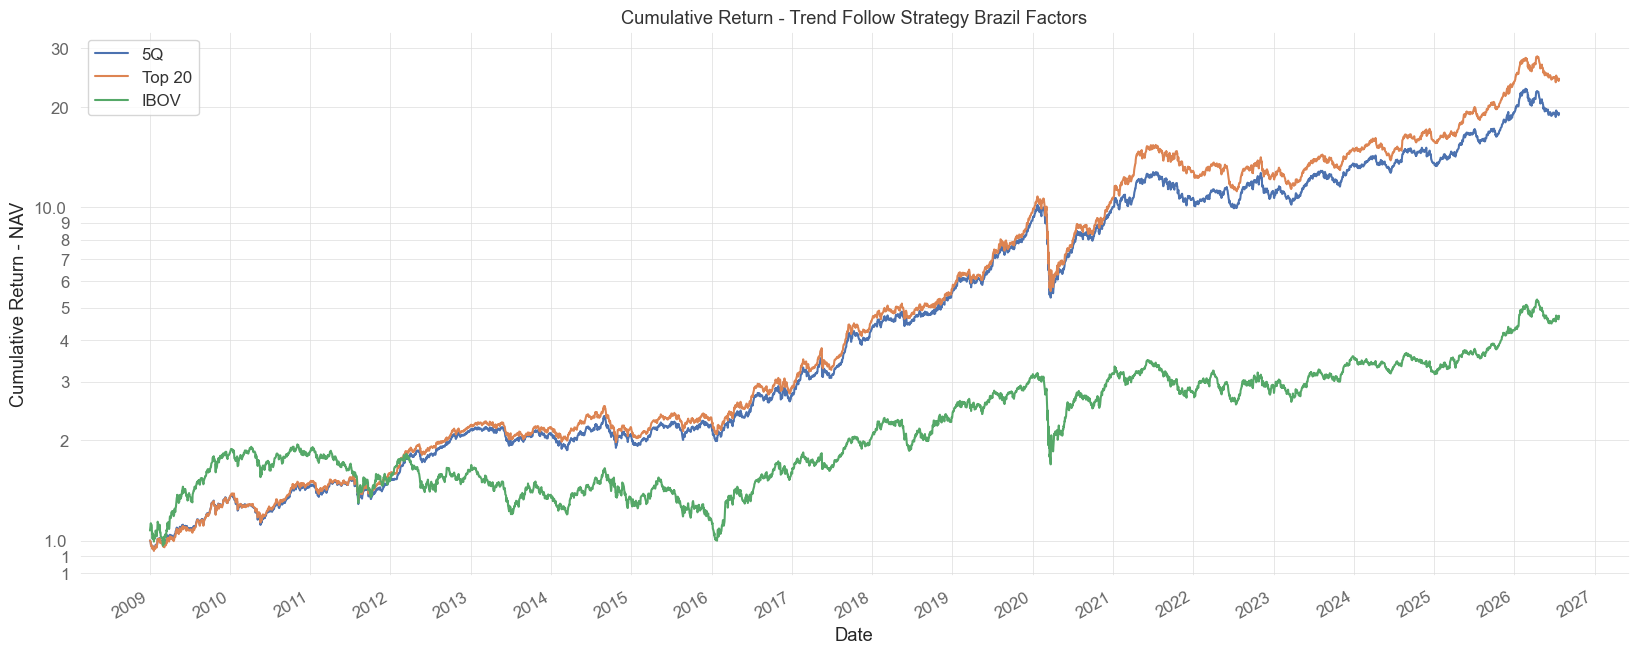

In [13]:
# sig_mean = stock_trend_signal_adj.get(['Profitability Composite', 'Value Composite', 'Growth Composite', 'Momentum', 'Low Vol']).mean(axis = 1)
# sig_sum = stock_trend_signal_adj.get(['Profitability Composite', 'Value Composite', 'Growth Composite', 'Momentum', 'Low Vol']).sum(axis = 1)
# sig_wgts = stock_trend_signal_adj.get(['Profitability Composite', 'Value Composite', 'Growth Composite', 'Momentum', 'Low Vol']).div(sig_sum, axis = 0).fillna(1/5).mul(sig_mean, axis = 0)
# ret_test = factors_quintiles_returns_df.mul(sig_wgts.shift(0)).sum(axis = 1).loc[date(2012,1,1):]

quintiles_returns_df = pd.DataFrame(quintiles_returns).dropna(how = 'all')
quintiles_returns_df[['5Q', 'Top 20']].add(1).cumprod().plot(figsize = (20,8), title = 'Cumulative Return - Trend Follow Strategy Brazil Factors', label = 'Trend Follow')
benchmarks['IBOV'].loc[quintiles_returns_df.index].add(1).cumprod().plot(figsize = (20,8), title = 'Cumulative Return - Trend Follow Strategy Brazil Factors', label = 'IBOV')

plt.legend()
plt.yscale('log')
plt.ylabel('Cumulative Return - NAV')
plt.xlabel('Date')

# Adjusts the number of ticks on the Y axis
plt.gca().yaxis.set_major_locator(ticker.LogLocator(base=10.0))  # Major ticks
plt.gca().yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs = 'auto'))  # Minor ticks

# Formats the Y axis values for better readability
plt.gca().yaxis.set_major_formatter(ticker.ScalarFormatter())
plt.gca().yaxis.set_minor_formatter(ticker.ScalarFormatter())

# Sets the X axis spacing to 1 year
plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))  # Major ticks every 1 year
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  # Formats the dates to show only the year

# Adds grid lines for the major and minor ticks
plt.grid(True, which='both')

print('Annualized return - Trend Follow:\n', quintiles_returns_df.mean() * 252)
print('Annualized volatility - Trend Follow:\n', quintiles_returns_df.std() * np.sqrt(252))

<Axes: title={'center': 'Drawdown - Trend Follow Strategy Brazil Factors'}, xlabel='Date'>

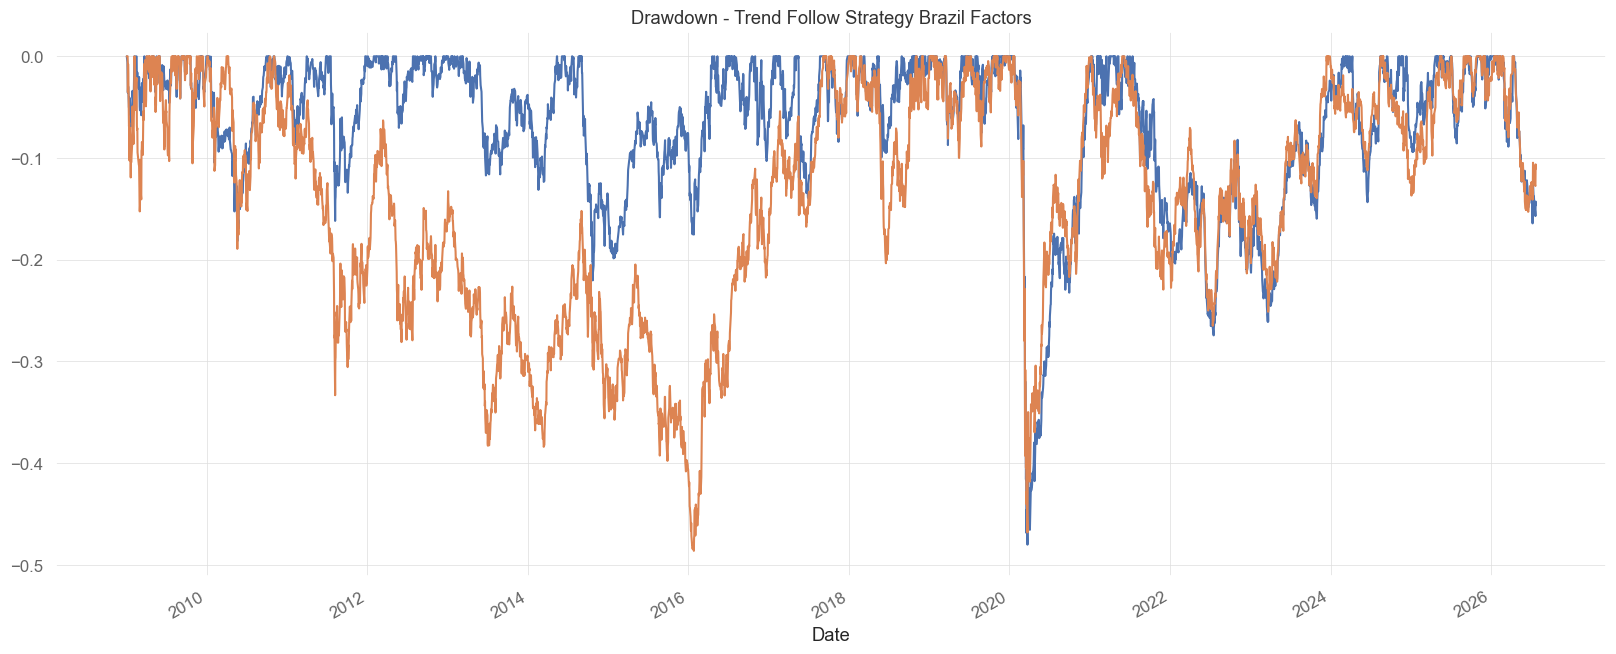

In [14]:
qs.stats.to_drawdown_series(quintiles_returns_df['Top 20']).plot(figsize = (20,8), title = 'Drawdown - Trend Follow Strategy Brazil Factors', label = 'Trend Follow')
qs.stats.to_drawdown_series(benchmarks['IBOV'].loc[quintiles_returns_df.index]).plot(figsize = (20,8), title = 'Drawdown - Trend Follow Strategy Brazil Factors', label = 'IBOV')

In [15]:
monthly_returns = quintiles_returns_df.resample('ME').agg(lambda t: t.add(1).prod() - 1)
monthly_returns = monthly_returns.pivot_table(index = monthly_returns.index.year, columns = monthly_returns.index.month, values = 'Top 20')
monthly_returns.columns = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_returns['YTD'] = monthly_returns.apply(lambda x: (x.add(1).prod() - 1), axis = 1)
monthly_returns.fillna(0).map('{:,.2%}'.format)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,YTD
Date,,,,,,,,,,,,,
2009,-4.13%,3.51%,0.72%,5.46%,4.13%,-2.44%,4.69%,1.94%,5.91%,1.16%,4.94%,4.80%,34.65%
2010,-3.18%,-3.04%,1.59%,-3.45%,-3.37%,4.21%,6.46%,-0.89%,5.15%,6.02%,-0.11%,1.86%,10.98%
2011,-5.05%,0.98%,5.11%,0.04%,0.09%,2.17%,-2.74%,-2.87%,-3.50%,4.82%,3.79%,3.89%,6.23%
2012,1.56%,10.98%,4.27%,3.16%,-3.87%,3.02%,2.22%,1.91%,4.08%,2.84%,0.95%,3.16%,39.41%
2013,1.61%,0.58%,0.53%,-2.40%,-0.27%,-5.92%,0.17%,-1.50%,1.05%,6.22%,-1.13%,0.52%,-0.97%
2014,-5.40%,-1.42%,4.69%,2.18%,2.73%,4.60%,-0.36%,8.02%,-12.74%,-2.71%,3.18%,-1.44%,-0.36%
2015,-7.05%,4.58%,4.11%,3.78%,0.58%,2.45%,0.29%,-6.88%,3.64%,-1.09%,3.39%,0.01%,7.13%
2016,-5.35%,3.66%,3.56%,8.75%,-3.64%,8.59%,9.23%,-4.33%,-1.01%,9.98%,-2.49%,-4.07%,23.06%
2017,10.12%,7.25%,-3.49%,6.45%,-2.65%,-2.79%,7.06%,11.92%,7.28%,1.01%,-1.99%,8.30%,58.28%


In [16]:
monthly_returns = benchmarks.resample('ME').agg(lambda t: t.add(1).prod() - 1)
monthly_returns = monthly_returns.pivot_table(index = monthly_returns.index.year, columns = monthly_returns.index.month, values = 'IBOV')
monthly_returns.columns = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_returns['YTD'] = monthly_returns.apply(lambda x: (x.add(1).prod() - 1), axis = 1)
monthly_returns.fillna(0).map('{:,.2%}'.format)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,YTD
Date,,,,,,,,,,,,,
2007,-1.63%,-1.68%,4.36%,6.88%,6.77%,4.06%,-0.39%,0.84%,10.67%,8.02%,-3.54%,1.40%,40.77%
2008,-6.88%,6.72%,-3.97%,11.32%,6.96%,-10.44%,-8.48%,-6.43%,-11.03%,-24.80%,-1.77%,2.61%,-41.22%
2009,4.66%,-2.84%,7.18%,15.55%,12.49%,-3.26%,6.41%,3.15%,8.90%,0.05%,8.93%,2.30%,82.66%
2010,-4.65%,1.68%,5.82%,-4.04%,-6.64%,-3.35%,10.80%,-3.51%,6.58%,1.79%,-4.20%,2.36%,1.04%
2011,-3.94%,1.22%,1.79%,-3.58%,-2.29%,-3.43%,-5.74%,-3.96%,-7.38%,11.49%,-2.51%,-0.21%,-18.11%
2012,11.13%,4.34%,-1.98%,-4.17%,-11.86%,-0.25%,3.21%,1.72%,3.70%,-3.56%,0.71%,6.05%,7.40%
2013,-1.95%,-3.91%,-1.87%,-0.78%,-4.30%,-11.31%,1.64%,3.68%,4.65%,3.66%,-3.27%,-1.86%,-15.50%
2014,-7.51%,-1.14%,7.05%,2.40%,-0.75%,3.76%,5.00%,9.78%,-11.70%,0.95%,0.07%,-8.52%,-2.91%
2015,-6.20%,9.97%,-0.84%,9.93%,-6.17%,0.61%,-4.17%,-8.33%,-3.36%,1.80%,-1.63%,-3.93%,-13.31%


In [17]:
# Factor exposure of the portfolio
returns_ff = pd.merge(quintiles_returns_df['Top 20'], ff_factors[["Mkt_RF", "SMB", "HML", "RMW", "CMA", "Risk_Free"]], how = 'left', left_index = True, right_index = True).dropna()
returns_ff['Excess_Return'] = returns_ff['Top 20'] - returns_ff['Risk_Free']
monthly_returns = returns_ff.resample('ME').apply(lambda x: (x + 1).prod() - 1)

Y = monthly_returns['Excess_Return']
X = monthly_returns[['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA']]
X = sm.add_constant(X)  # Adds a constant for the intercept
model = sm.OLS(Y, X).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          Excess_Return   R-squared:                       0.651
Model:                            OLS   Adj. R-squared:                  0.642
Method:                 Least Squares   F-statistic:                     76.31
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           6.69e-45
Time:                        00:38:57   Log-Likelihood:                 421.76
No. Observations:                 211   AIC:                            -831.5
Df Residuals:                     205   BIC:                            -811.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0085      0.002      3.699      0.000       0.004       0.013
Mkt_RF         0.7737      0.046     16.865      0.000       0.683       0.864
SMB            0.2678      0.059      4.574      0.000       0.152       0.383
HML           -0.3728      0.075     -4.978      0.000      -0.520      -0.225
RMW            0.0909      0.074      1.230      0.220      -0.055       0.237
CMA            0.2244      0.074      3.020      0.003       0.078       0.371
==============================================================================
Omnibus:                        8.592   Durbin-Watson:                   1.952
Prob(Omnibus):                  0.014   Jarque-Bera (JB):               14.056
Skew:                           0.182   Prob(JB):                     0.000887
Kurtosis:                       4.211   Cond. No.                         41.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [18]:
# Turnover of the top 20 stocks: share of the portfolio replaced on each daily rebalance, with equal weights
held = top_20.loc[top_20.sum(axis = 1) > 0]
names_replaced = held.diff().clip(lower = 0).sum(axis = 1).iloc[1:]
daily_turnover = names_replaced / 20
print(f'Top 20: about {names_replaced.mean():.2f} stocks replaced per day, a turnover of {daily_turnover.mean():.1%} per day, {daily_turnover.mean() * 21:.0%} per month and {daily_turnover.mean() * 252:.0%} per year')

Top 20: about 1.01 stocks replaced per day, a turnover of 5.0% per day, 106% per month and 1270% per year


The same two portfolios are also run with a monthly rebalance, on the first business day of each month, as the other strategies of the repository. The signal is the one of the day before the rebalance.

In [19]:
# Monthly rebalancing dates, as in 05_
monthly_rebalance_dates = [date(year, month, 1) for year in range(2009, 2027) for month in range(1,13, 1)]
monthly_rebalance_dates = [cal.following(ref_date) for ref_date in monthly_rebalance_dates if ref_date <= prices_df.index[-1].date()]

monthly_stock_returns = {'5Q': backtest_quintiles(prices_df, quintiles['5Q'], monthly_rebalance_dates, market_value),
                         'Top 20': backtest_quintiles(prices_df, top_20, monthly_rebalance_dates, market_value)}

# Turnover of the monthly top 20: share of the portfolio replaced on each rebalance, with equal weights
monthly_signal_dates = [prices_df.index[prices_df.index.get_loc(pd.Timestamp(dt)) - 1] for dt in monthly_rebalance_dates if pd.Timestamp(dt) in prices_df.index]
monthly_held = top_20.loc[monthly_signal_dates]
monthly_held = monthly_held.loc[monthly_held.sum(axis = 1) > 0]
print(f'Monthly top 20: {monthly_held.diff().clip(lower = 0).sum(axis = 1).iloc[1:].mean() / 20:.0%} of the portfolio replaced per month, before the drift of the weights')

Monthly top 20: 46% of the portfolio replaced per month, before the drift of the weights


# Long legs of the factors

For each factor, the long leg is its top quintile, rebalanced on the first business day of each month with equal weights, as in `04_`.

In [20]:
# Creates a list with all rebalancing dates
rebalance_dates = [date(year, month, 1) for year in range(2009, 2027) for month in range(1,13, 1)]

# Checks whether the date is a business day, if not, returns the next business day
rebalance_dates = [cal.following(ref_date) for ref_date in rebalance_dates if ref_date <= prices_df.index[-1].date()]

legs = dict()
leg_returns = dict()
for factor_name in tqdm(trend_factors):
    legs[factor_name] = get_quintiles(0.8, 1.0, factors_dict[factor_name])
    leg_returns[factor_name] = backtest_quintiles(prices_df, legs[factor_name], rebalance_dates, market_value)

# A leg earns zero before it holds its first stock; those days are set to NaN so that they do not enter the trend
leg_returns = pd.DataFrame(leg_returns)
leg_returns = leg_returns.where(leg_returns.ne(0).cummax())

  0%|          | 0/6 [00:00<?, ?it/s]

 17%|█▋        | 1/6 [00:03<00:15,  3.03s/it]

 33%|███▎      | 2/6 [00:06<00:12,  3.03s/it]

 50%|█████     | 3/6 [00:09<00:09,  3.00s/it]

 67%|██████▋   | 4/6 [00:11<00:05,  2.98s/it]

 83%|████████▎ | 5/6 [00:14<00:02,  2.96s/it]

100%|██████████| 6/6 [00:17<00:00,  2.96s/it]

100%|██████████| 6/6 [00:17<00:00,  2.98s/it]

# Trend of the long legs

The trend indicator is the one of `05_`: four spreads between exponential moving averages of the cumulative return, each normalized by its standard deviation over 252 days and passed through the hyperbolic tangent, then averaged. It goes from -1 to 1 and is in `brfactors/trend.py`.

A factor can only be held once its indicator exists, about 252 days after its leg starts, so the factors enter the strategy over time.

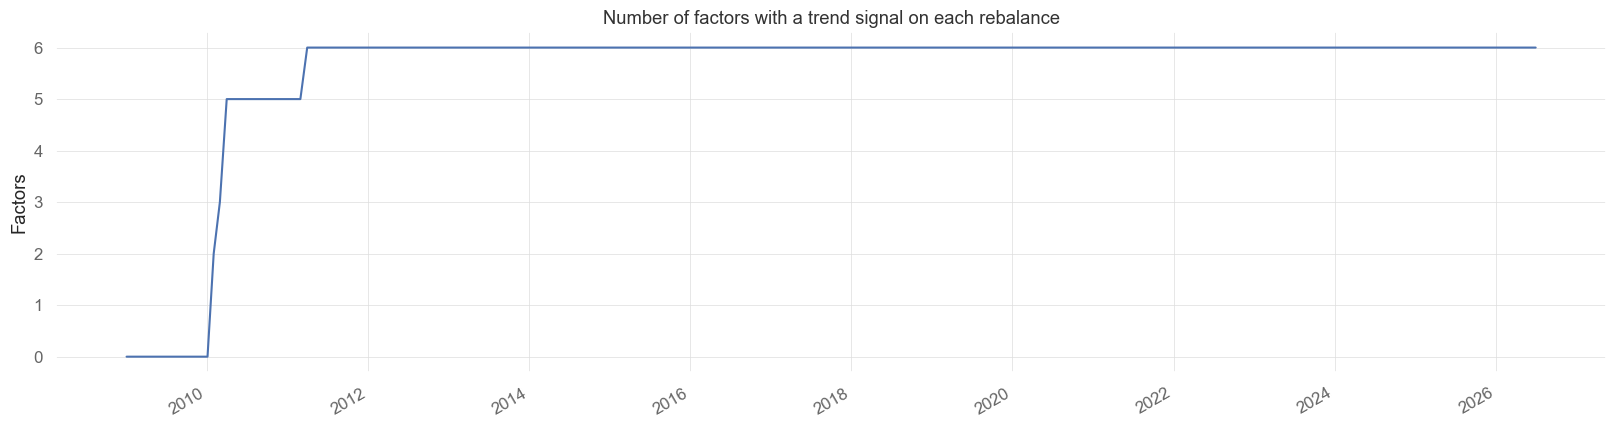

In [21]:
signals = trend_signal(leg_returns)

# Dates of the signals: the day before each rebalance
trade_dates = [pd.Timestamp(dt) for dt in rebalance_dates if pd.Timestamp(dt) in prices_df.index]
signal_dates = [prices_df.index[prices_df.index.get_loc(dt) - 1] for dt in trade_dates]

monthly_signal = signals.loc[signal_dates]
monthly_signal.index = trade_dates

monthly_signal.notna().sum(axis = 1).plot(figsize = (20,5), title = 'Number of factors with a trend signal on each rebalance')
plt.ylabel('Factors')
plt.grid(True)

Text(0.5, 1.0, 'Trend signal of the long legs on each rebalance')

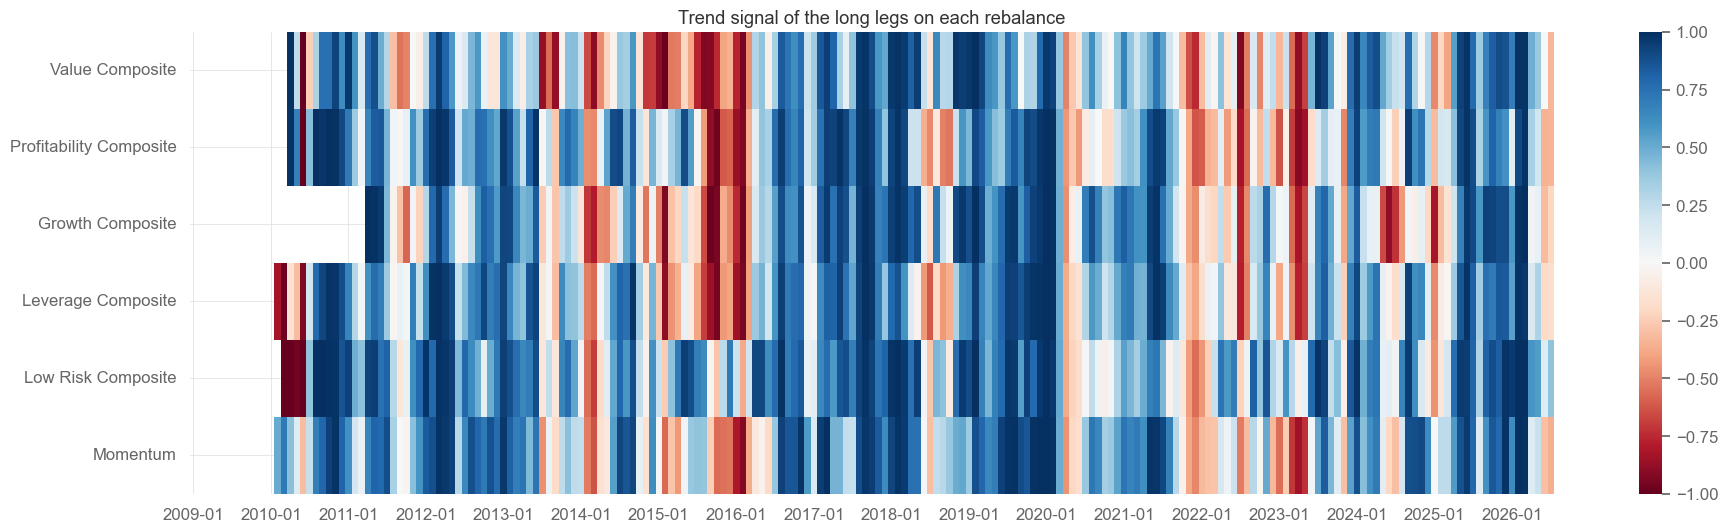

In [22]:
heatmap_signal = monthly_signal.copy()
heatmap_signal.index = [dt.strftime('%Y-%m') for dt in trade_dates]

plt.figure(figsize = (22,6))
sns.heatmap(heatmap_signal.T, cmap = 'RdBu', center = 0, vmin = -1, vmax = 1, xticklabels = 12)
plt.title('Trend signal of the long legs on each rebalance')

# Allocation rule

On each rebalance, the rule uses the trend signal `s` of each eligible factor on the day before:
- a factor with a negative trend gets no weight;
- the others get weights proportional to their trend, `max(s, 0)`, normalized to add up to 100%.

The factor with the strongest trend therefore always has the largest weight, and a factor enters the basket as soon as its trend turns positive. The portfolio is always fully invested: in a month when no factor has a positive trend, the eligible factors get equal weights.

The control holds all eligible factors with equal weights, with no trend.

In [23]:
def trend_weights(s):
    # Returns the weight of each factor, given the trend signals of the day before the rebalance
    s = s.dropna()
    if len(s) == 0:
        return pd.Series(dtype = float)
    positive = s.clip(lower = 0)
    if positive.sum() > 0:
        return positive / positive.sum()
    return pd.Series(1 / len(s), index = s.index)

def equal_weights(s):
    # Control: all eligible factors with equal weights
    s = s.dropna()
    return pd.Series(1 / len(s), index = s.index) if len(s) > 0 else pd.Series(dtype = float)

rules = {'Trend': trend_weights, 'All equal': equal_weights}

# Factor weights of each rule, indexed by the rebalancing date
factor_weights = {name: pd.DataFrame({dt: rule(monthly_signal.loc[dt]) for dt in trade_dates}).T.reindex(index = trade_dates, columns = trend_factors).fillna(0)
                  for name, rule in rules.items()}

# The strategy starts on the first rebalance with an eligible factor
first_rebalance = factor_weights['Trend'].sum(axis = 1).gt(0).idxmax()
start_date = prices_df.index[prices_df.index.get_loc(first_rebalance) + 1]
first_signal_date = signal_dates[trade_dates.index(first_rebalance)]

no_positive = (monthly_signal.loc[first_rebalance:].clip(lower = 0).sum(axis = 1) == 0).sum()
print(f'First rebalance: {first_rebalance.date()}, returns from {start_date.date()}')
print(f'Rebalances with no positive trend (equal weights): {no_positive} of {len(monthly_signal.loc[first_rebalance:])}')

First rebalance: 2010-02-01, returns from 2010-02-02
Rebalances with no positive trend (equal weights): 18 of 198


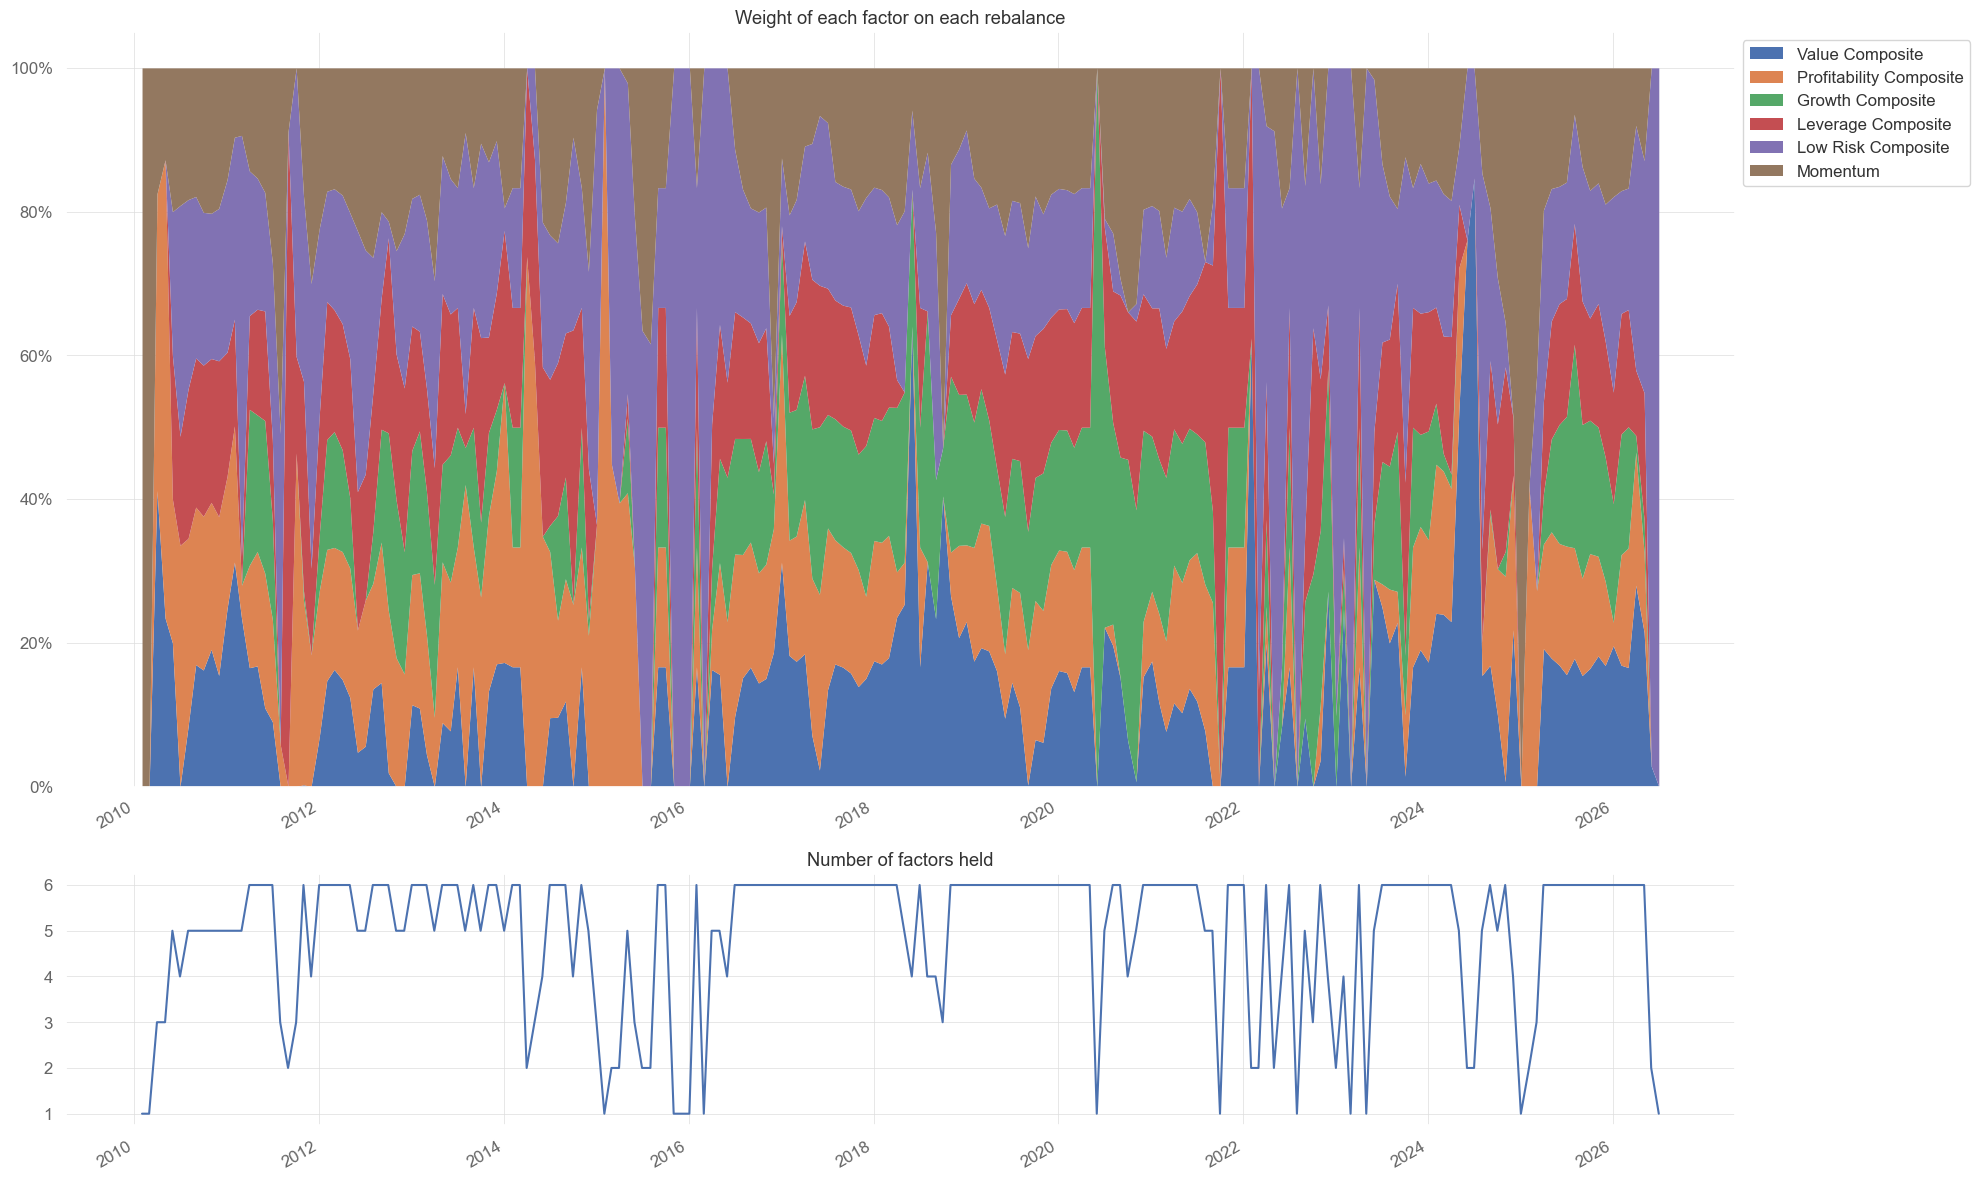

In [24]:
# Weight of each factor over time
fig, axes = plt.subplots(2, 1, figsize = (20, 12), gridspec_kw = {'height_ratios': [3, 1]})
factor_weights['Trend'].loc[first_rebalance:].plot.area(ax = axes[0], linewidth = 0, title = 'Weight of each factor on each rebalance')
axes[0].yaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals = 0))
axes[0].legend(loc = 'upper left', bbox_to_anchor = (1, 1))
(factor_weights['Trend'].loc[first_rebalance:] > 0).sum(axis = 1).plot(ax = axes[1], title = 'Number of factors held')
for ax in axes:
    ax.grid(True)
plt.tight_layout()

In [25]:
# Average weight of each factor and share of the rebalances in which it is held
W = factor_weights['Trend'].loc[first_rebalance:]
pd.DataFrame({'Average weight': W.mean(), 'Held': (W > 0).mean(), 'Largest weight': W.max()}).sort_values('Average weight', ascending = False).map('{:.1%}'.format)

,Average weight,Held,Largest weight
Low Risk Composite,25.3%,91.9%,100.0%
Momentum,17.5%,85.9%,100.0%
Profitability Composite,16.1%,81.8%,100.0%
Leverage Composite,15.1%,82.3%,100.0%
Value Composite,13.6%,77.8%,84.7%
Growth Composite,12.5%,72.7%,100.0%


## Stage 1: factor return series

The portfolio return is `sum(w_f * r_f)`, where `r_f` is the daily return of the long leg. The weights decided on the rebalance earn returns from the next day on and stay fixed until the next rebalance, so this is an approximation of the real portfolio.

In [26]:
cdi = benchmarks['CDI'].reindex(prices_df.index)

def factor_series_return(W):
    # Stage 1 return of a set of factor weights
    Wd = W.reindex(prices_df.index).ffill().shift(1)
    return (Wd * leg_returns[W.columns].fillna(0)).sum(axis = 1).loc[start_date:]

stage1_returns = {name: factor_series_return(W) for name, W in factor_weights.items()}

## Stage 2: single basket

The weight of each stock is the sum, over the factors held, of the factor weight divided by the number of stocks in its leg: `W = sum(w_f * L_f / n_f)`. `backtest_quintiles` then runs the basket like the portfolios of the other notebooks.

In [27]:
def stock_weights(W):
    # Returns the stock weights on the day before each rebalance, which is the day the engine reads
    weights = pd.DataFrame(0.0, index = signal_dates, columns = prices_df.columns)
    for dt, dtm1 in zip(trade_dates, signal_dates):
        for factor, wf in W.loc[dt].items():
            if wf <= 0:
                continue
            stocks = legs[factor].loc[dtm1]
            stocks = stocks[stocks > 0]
            if len(stocks) > 0:
                weights.loc[dtm1, stocks.index] += wf / len(stocks)
    return weights

basket_weights = {name: stock_weights(W) for name, W in factor_weights.items()}
stage2_returns = {name: backtest_quintiles(prices_df, weights, rebalance_dates, market_value).loc[start_date:] for name, weights in basket_weights.items()}

### Control: the Combination of `05_`

The Combination of `05_multi_factor_strategy`, rebuilt here over the same window. Its signals are those of `05_`, which differ from those of `04_`: momentum and volatility are trimmed at 2 standard deviations, the Profitability composite leaves out CFOA, the Value composite leaves out FCF to Price, and the Magic Formula ranking also uses volatility and momentum.

In [28]:
# Signals of 05_multi_factor_strategy
z_mom_05 = z_mom.where((z_mom >= -2) & (z_mom <= 2))
z_vol_05 = z_vol.where((z_vol >= -2) & (z_vol <= 2))
z_profitability_05 = z_roe + z_gpoa + z_acc + z_roa
z_value_05 = z_ev + z_ey + z_bp + z_sales
z_mf_05 = -stats.zscore(roc_mf.rank(axis=1, ascending=False) +
                        earnings_yield_mf.rank(axis=1, ascending=False) +
                        debt_ebit_mf.rank(axis=1, ascending=True) +
                        volatility.rank(axis = 1, ascending = True) +
                        momentum.rank(axis=1, ascending=False), axis=1, nan_policy='omit')
z_mf_05 = pd.DataFrame(z_mf_05, columns=roc_mf.columns, index=roc_mf.index)

# Stock selection and backtest, as in 05_
short_mf, long_mf = get_longshort_amount(10, z_mf_05) # Magic Formula
short_momvol, long_momvol = get_longshort_amount(10, -z_vol_05, use_filter = True, filter_signal = [z_mom_05], filter_percentile = [0.8]) # LowVol Momentum
short_quality, long_quality = get_longshort_amount(10, z_profitability_05 + z_value_05, use_filter = True, filter_signal = [z_safety, z_growth], filter_percentile = [0.2, 0.2]) # Quality
ret_comb = backtest_quintiles(prices_df, long_mf + long_momvol + long_quality, rebalance_dates, market_value)

print(f"Combination from January 2009, annualized return: {ret_comb.dropna().add(1).prod() ** (252 / len(ret_comb.dropna())) - 1:.1%}")

Combination from January 2009, annualized return: 17.1%


# Results

Statistics from the first month with a signal to the end of the sample. The Sharpe ratio is the mean excess return over the CDI divided by the volatility, as in the other notebooks. The alpha and the market beta come from a regression of the monthly excess returns on the NEFIN factors (market, SMB, HML and WML), as in `05_`.

In [29]:
def statistics(ret):
    ret = ret.dropna()
    excess = ret - cdi.loc[ret.index]
    return {'Total Return': ret.add(1).prod() - 1,
            'Annualized Return': ret.add(1).prod() ** (252 / len(ret)) - 1,
            'Volatility': ret.std() * np.sqrt(252),
            'Sharpe Ratio': excess.mean() * 252 / (ret.std() * np.sqrt(252)),
            'Max Drawdown': qs.stats.max_drawdown(ret)}

def nefin_regression(ret):
    returns_nefin = pd.merge(ret.rename('Daily return'), nefin[['Rm_minus_Rf', 'Risk_Free', 'SMB', 'HML', 'WML']], how = 'left', left_index = True, right_index = True).dropna()
    returns_nefin['Excess_Return'] = returns_nefin['Daily return'] - returns_nefin['Risk_Free']
    monthly = returns_nefin.resample('ME').apply(lambda x: (x + 1).prod() - 1)
    model = sm.OLS(monthly['Excess_Return'], sm.add_constant(monthly[['Rm_minus_Rf', 'SMB', 'HML', 'WML']])).fit()
    return {'Alpha (month)': model.params['const'], 'Alpha t-stat': model.tvalues['const'], 'Market beta': model.params['Rm_minus_Rf']}

strategies = {'Trend': stage2_returns['Trend'], 'All equal': stage2_returns['All equal'], '05 Combination': ret_comb.loc[start_date:]}
benchmark_returns = {'IBOV': benchmarks['IBOV'].loc[start_date:], 'SMLL': benchmarks['SMLL'].loc[start_date:], 'CDI': benchmarks['CDI'].loc[start_date:]}

results = dict()
for name, ret in strategies.items():
    row = statistics(ret)
    row.update(nefin_regression(ret))
    if name in stage1_returns:
        row['Stage 1 Return'] = statistics(stage1_returns[name])['Annualized Return']
    results[name] = row
single_stock_returns = {'Single stocks, trend top 20 (daily)': quintiles_returns_df['Top 20'],
                        'Single stocks, trend top quintile (daily)': quintiles_returns_df['5Q'],
                        'Single stocks, trend top 20 (monthly)': monthly_stock_returns['Top 20'],
                        'Single stocks, trend top quintile (monthly)': monthly_stock_returns['5Q']}
for name, ret in single_stock_returns.items():
    row = statistics(ret.loc[start_date:])
    row.update(nefin_regression(ret.loc[start_date:]))
    results[name] = row
for name, ret in benchmark_returns.items():
    results[name] = statistics(ret)

results = pd.DataFrame(results).T
results_fmt = results.copy()
for col in ['Total Return', 'Annualized Return', 'Stage 1 Return', 'Volatility', 'Max Drawdown']:
    results_fmt[col] = results_fmt[col].map(lambda x: '' if pd.isna(x) else f'{x:.1%}')
results_fmt['Alpha (month)'] = results_fmt['Alpha (month)'].map(lambda x: '' if pd.isna(x) else f'{x:.2%}')
for col in ['Sharpe Ratio', 'Alpha t-stat', 'Market beta']:
    results_fmt[col] = results_fmt[col].map(lambda x: '' if pd.isna(x) else f'{x:.2f}')
results_fmt[['Total Return', 'Annualized Return', 'Stage 1 Return', 'Volatility', 'Sharpe Ratio', 'Max Drawdown', 'Alpha (month)', 'Alpha t-stat', 'Market beta']].T

,Trend,All equal,05 Combination,"Single stocks, trend top 20 (daily)","Single stocks, trend top quintile (daily)","Single stocks, trend top 20 (monthly)","Single stocks, trend top quintile (monthly)",IBOV,SMLL,CDI
Total Return,601.4%,565.0%,994.4%,1734.8%,1374.4%,988.9%,1112.8%,165.5%,88.5%,370.6%
Annualized Return,12.6%,12.2%,15.7%,19.4%,17.8%,15.7%,16.4%,6.1%,3.9%,9.9%
Stage 1 Return,12.6%,12.2%,,,,,,,,
Volatility,19.4%,19.8%,19.2%,18.9%,18.9%,19.9%,19.6%,22.8%,22.9%,0.2%
Sharpe Ratio,0.22,0.21,0.36,0.53,0.46,0.36,0.39,-0.04,-0.13,0.00
Max Drawdown,-45.6%,-45.7%,-45.3%,-48.0%,-47.4%,-51.1%,-50.0%,-48.6%,-54.0%,0.0%
Alpha (month),0.32%,0.40%,0.52%,0.62%,0.54%,0.43%,0.46%,,,
Alpha t-stat,2.22,3.05,3.15,2.97,3.05,2.00,2.48,,,
Market beta,0.94,0.94,0.90,0.87,0.87,0.92,0.93,,,


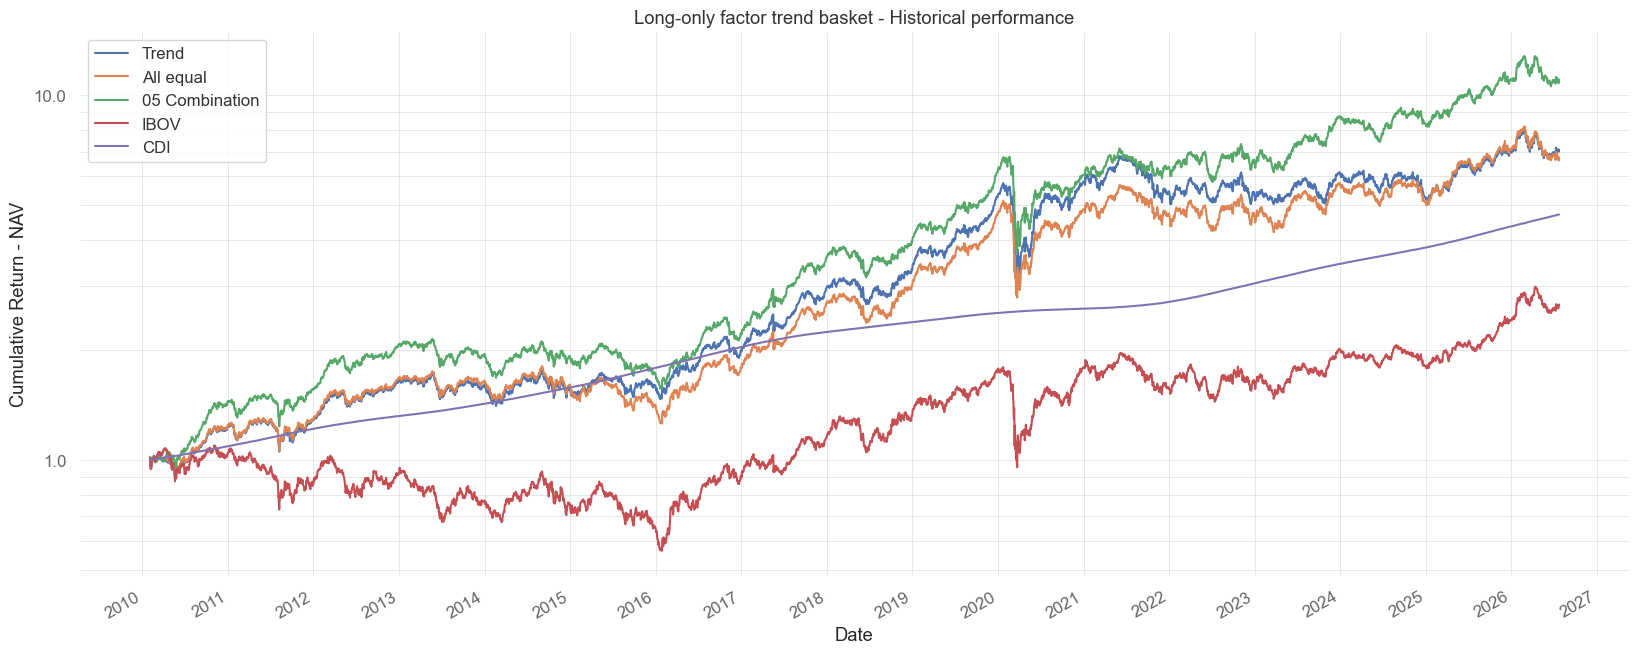

In [30]:
# Historical performance
for name, ret in strategies.items():
    ret.add(1).cumprod().plot(figsize = (20,8), label = name)
for name in ['IBOV', 'CDI']:
    benchmark_returns[name].add(1).cumprod().plot(label = name)

plt.title('Long-only factor trend basket - Historical performance')
plt.legend()
plt.ylabel('Cumulative Return - NAV')
plt.xlabel('Date')
plt.yscale('log')
plt.gca().yaxis.set_major_formatter(ticker.ScalarFormatter())
plt.gca().yaxis.set_minor_formatter(ticker.NullFormatter())
plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.grid(True, which='both')

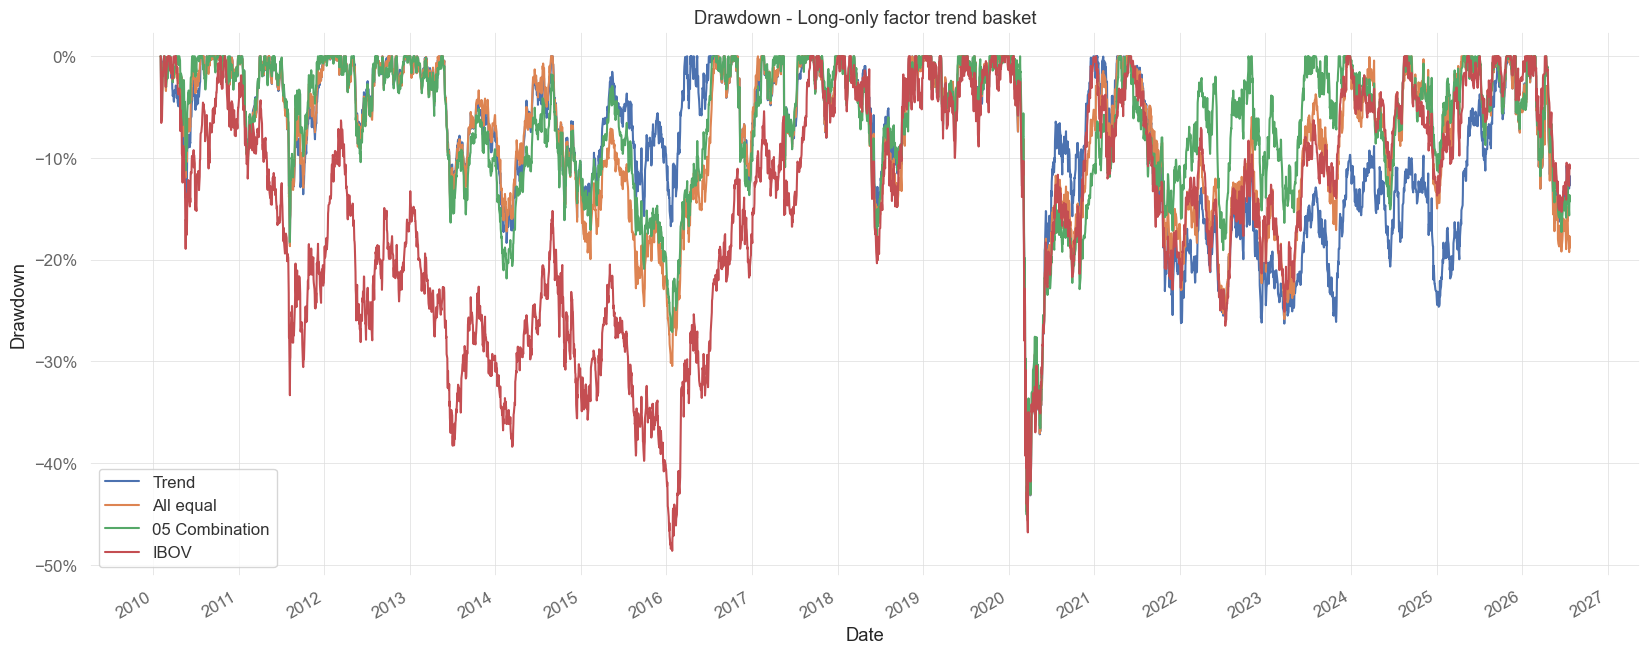

In [31]:
# Drawdowns
for name, ret in strategies.items():
    qs.stats.to_drawdown_series(ret.dropna()).plot(figsize = (20,8), label = name)
qs.stats.to_drawdown_series(benchmark_returns['IBOV']).plot(label = 'IBOV')

plt.title('Drawdown - Long-only factor trend basket')
plt.legend()
plt.ylabel('Drawdown')
plt.xlabel('Date')
plt.gca().yaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals = 0))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
plt.grid(True)

In [32]:
# Return in each calendar year
annual = pd.DataFrame({**strategies, 'IBOV': benchmark_returns['IBOV'], 'CDI': benchmark_returns['CDI']}).resample('YE').apply(lambda x: x.add(1).prod() - 1)
annual.index = annual.index.year
annual.map('{:.1%}'.format)

,Trend,All equal,05 Combination,IBOV,CDI
Date,,,,,
2010,23.1%,24.2%,44.6%,4.1%,9.0%
2011,4.5%,4.1%,7.7%,-18.1%,11.6%
2012,27.9%,29.6%,32.9%,7.4%,8.4%
2013,-2.4%,-1.5%,-5.7%,-15.5%,8.1%
2014,-2.0%,-2.9%,-1.4%,-2.9%,10.8%
2015,1.1%,-11.8%,-10.4%,-13.3%,13.2%
2016,25.5%,27.0%,29.0%,38.9%,14.0%
2017,47.7%,49.2%,60.4%,26.9%,10.0%
2018,12.7%,12.0%,10.9%,15.0%,6.4%


# Concentration

The measures below use the target weights of the stocks on each rebalance:
- **Stocks**: the number of different stocks in the basket;
- **Max weight**: the largest stock weight, on average and at its peak;
- **Effective N**: `1 / sum(w^2)`, the number of equally weighted stocks that would give the same concentration;
- **Top 10 share**: the weight of the 10 largest positions;
- **Turnover**: half the sum of the absolute differences between the new weights and the weights of the month before after their drift, per rebalance.

In [33]:
# Prices used to drift the weights between two rebalances
prices_drift = prices_df.ffill()

def concentration_series(weights):
    W = weights.copy()
    W.index = trade_dates
    W = W.loc[first_rebalance:]
    W = W.div(W.sum(axis = 1), axis = 0).fillna(0)
    turnover = [np.nan]
    for dt0, dt1 in zip(W.index[:-1], W.index[1:]):
        drifted = (W.loc[dt0] * prices_drift.loc[dt1] / prices_drift.loc[dt0]).fillna(0)
        turnover.append(0.5 * (W.loc[dt1] - drifted / drifted.sum()).abs().sum())
    return pd.DataFrame({'Stocks': (W > 0).sum(axis = 1),
                         'Max weight': W.max(axis = 1),
                         'Effective N': 1 / (W ** 2).sum(axis = 1),
                         'Top 10 share': W.apply(lambda x: x.nlargest(10).sum(), axis = 1),
                         'Turnover': turnover}, index = W.index)

concentration = {name: concentration_series(weights) for name, weights in basket_weights.items()}
summary = pd.DataFrame({name: {'Stocks': c['Stocks'].mean(), 'Max weight': c['Max weight'].mean(), 'Max weight (peak)': c['Max weight'].max(),
                               'Effective N': c['Effective N'].mean(), 'Top 10 share': c['Top 10 share'].mean(), 'Turnover': c['Turnover'].mean()}
                        for name, c in concentration.items()}).T
for col in ['Max weight', 'Max weight (peak)', 'Top 10 share', 'Turnover']:
    summary[col] = summary[col].map('{:.1%}'.format)
for col in ['Stocks', 'Effective N']:
    summary[col] = summary[col].map('{:.0f}'.format)
summary

,Stocks,Max weight,Max weight (peak),Effective N,Top 10 share,Turnover
Trend,69,3.8%,6.9%,52,30.4%,28.9%
All equal,79,3.7%,50.0%,62,26.1%,17.8%


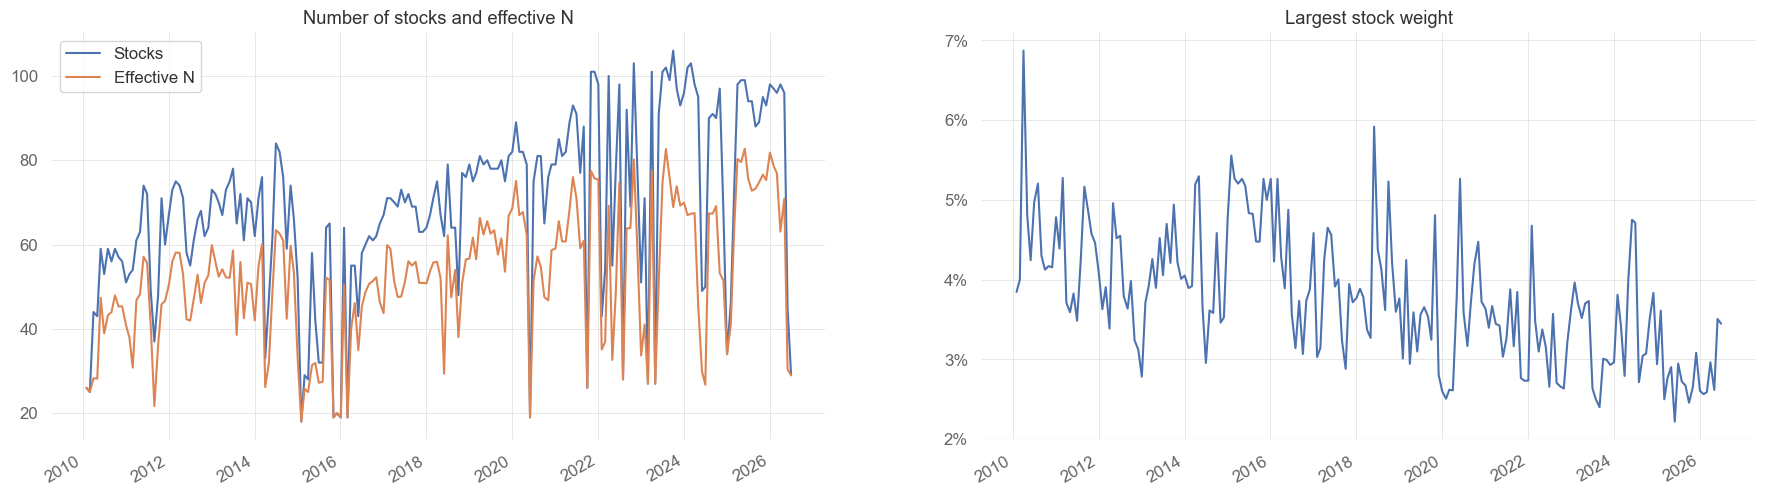

In [34]:
# Concentration of the trend basket over time
c = concentration['Trend']
fig, axes = plt.subplots(1, 2, figsize = (22, 6))
c[['Stocks', 'Effective N']].plot(ax = axes[0], title = 'Number of stocks and effective N')
c['Max weight'].plot(ax = axes[1], title = 'Largest stock weight')
axes[1].yaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals = 0))
for ax in axes:
    ax.grid(True)

In [35]:
# Weight of each sector in the trend basket, using the sector of the last index composition on or before the rebalance
sectors = companies.reset_index()[['Date', 'Ticker', 'Sector']].drop_duplicates()
sectors['Date'] = pd.to_datetime(sectors['Date'])

W = basket_weights['Trend'].copy()
W.index = trade_dates
W = W.loc[first_rebalance:]

by_date = []
for dt, w in W.iterrows():
    w = w[w > 0]
    sector_of = sectors[sectors['Date'] <= dt].sort_values('Date').groupby('Ticker')['Sector'].last()
    by_date.append(w.groupby(sector_of.reindex(w.index).fillna('Unknown')).sum() / w.sum())
by_date = pd.DataFrame(by_date).fillna(0)

pd.DataFrame({'Mean': by_date.mean(), 'Max': by_date.max()}).sort_values('Mean', ascending = False).map('{:.1%}'.format)

,Mean,Max
Sector,,
Consumo Cíclico,20.1%,36.4%
Utilidade Pública,18.5%,46.4%
Bens Industriais,12.0%,28.7%
Financeiro,11.0%,27.6%
Consumo não Cíclico,9.0%,19.8%
Materiais Básicos,8.1%,22.6%
Saúde,7.7%,17.1%
"Petróleo, Gás e Biocombustíveis",4.1%,16.9%
Comunicações,3.6%,7.6%


# Comparison with the Combination

The reference below is the equal-weighted investable universe: all the stocks of the SMLL and MLCX that pass the price and liquidity filters, rebalanced every month. It separates what the trend basket and the Combination share because they buy from the same universe from what each one adds over it.

In [36]:
# Equal-weighted investable universe
universe = (investable * has_price * volume_filter).reindex(index = prices_df.index, columns = prices_df.columns).fillna(0)
ret_universe = backtest_quintiles(prices_df, universe, rebalance_dates, market_value)

compare = pd.DataFrame({**strategies, 'EW universe': ret_universe, 'IBOV': benchmarks['IBOV']}).loc[start_date:].dropna()
compare_monthly = compare.resample('ME').apply(lambda x: (x + 1).prod() - 1)

print('Correlation of the monthly returns')
compare_monthly.corr().round(2)

Correlation of the monthly returns


,Trend,All equal,05 Combination,EW universe,IBOV
Trend,1.00,0.97,0.94,0.94,0.86
All equal,0.97,1.00,0.95,0.97,0.88
05 Combination,0.94,0.95,1.00,0.91,0.83
EW universe,0.94,0.97,0.91,1.00,0.92
IBOV,0.86,0.88,0.83,0.92,1.00


In [37]:
# Returns over the equal-weighted universe
active = compare_monthly[list(strategies)].sub(compare_monthly['EW universe'], axis = 0)

r2_universe = {col: sm.OLS(compare_monthly[col], sm.add_constant(compare_monthly['EW universe'])).fit().rsquared for col in strategies}
print(pd.DataFrame({'Mean over the universe (year)': active.mean().mul(12).map('{:.1%}'.format),
                    'Tracking error': active.std().mul(np.sqrt(12)).map('{:.1%}'.format),
                    'R2 on the universe': pd.Series(r2_universe).map('{:.2f}'.format)}))
print('\nCorrelation of the returns over the universe')
active.corr().round(2)

               Mean over the universe (year) Tracking error R2 on the universe
Trend                                   5.0%           7.8%               0.88
All equal                               4.8%           5.6%               0.95
05 Combination                          7.8%           9.4%               0.82

Correlation of the returns over the universe


,Trend,All equal,05 Combination
Trend,1.00,0.84,0.71
All equal,0.84,1.00,0.82
05 Combination,0.71,0.82,1.00


In [38]:
# Holdings overlap with the Combination on each rebalance: sum over the stocks of the smaller of the two weights
comb_holdings = long_mf + long_momvol + long_quality

overlap = dict()
for name, weights in basket_weights.items():
    values = []
    for dtm1 in signal_dates[trade_dates.index(first_rebalance):]:
        w = weights.loc[dtm1]
        w = w[w > 0] / w[w > 0].sum()
        c = comb_holdings.loc[dtm1]
        c = c[c > 0] / c[c > 0].sum()
        if len(w) > 0 and len(c) > 0:
            values.append(np.minimum(w, c.reindex(w.index).fillna(0)).sum())
    overlap[name] = np.mean(values)

pd.Series(overlap).map('{:.1%}'.format)

Trend        36.8%
All equal    37.0%
dtype: object

# Robustness

Two checks of the allocation, on the Stage 1 returns:
- **Signal lag**: the signal is taken some trading days before the usual date. A look-ahead error would make the result fall at once with one day of lag; a real trend signal fades slowly.
- **Shuffled signals**: on each rebalance, the trend signals are shuffled among the eligible factors before the weights are set, 500 times. The weights keep the same shape, but they no longer follow each factor's own trend.

In [39]:
def lagged_weights(lag):
    # Trend weights using the signal 'lag' trading days before the usual date
    W = dict()
    for dt, dtm1 in zip(trade_dates, signal_dates):
        W[dt] = trend_weights(signals.iloc[prices_df.index.get_loc(dtm1) - lag])
    return pd.DataFrame(W).T.reindex(index = trade_dates, columns = trend_factors).fillna(0)

lag_test = pd.DataFrame({f'{lag} days': statistics(factor_series_return(lagged_weights(lag))) for lag in [0, 1, 5, 21, 63]}).T[['Annualized Return', 'Sharpe Ratio']]
lag_test['Annualized Return'] = lag_test['Annualized Return'].map('{:.1%}'.format)
lag_test['Sharpe Ratio'] = lag_test['Sharpe Ratio'].map('{:.2f}'.format)
lag_test

,Annualized Return,Sharpe Ratio
0 days,12.6%,0.22
1 days,12.8%,0.23
5 days,12.2%,0.20
21 days,13.2%,0.25
63 days,11.5%,0.17


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 1/500 [00:00<01:01,  8.16it/s]

  0%|          | 2/500 [00:00<01:01,  8.08it/s]

  1%|          | 3/500 [00:00<01:00,  8.15it/s]

  1%|          | 4/500 [00:00<01:00,  8.18it/s]

  1%|          | 5/500 [00:00<01:20,  6.18it/s]

... (493 outputs left out)

100%|█████████▉| 499/500 [01:05<00:00,  8.14it/s]

100%|██████████| 500/500 [01:05<00:00,  8.11it/s]

100%|██████████| 500/500 [01:05<00:00,  7.61it/s]

Shuffled signals: mean 12.1%, 5th percentile 10.6%, 95th percentile 13.8%, maximum 15.3%
Trend: 12.6%, above 68% of the draws


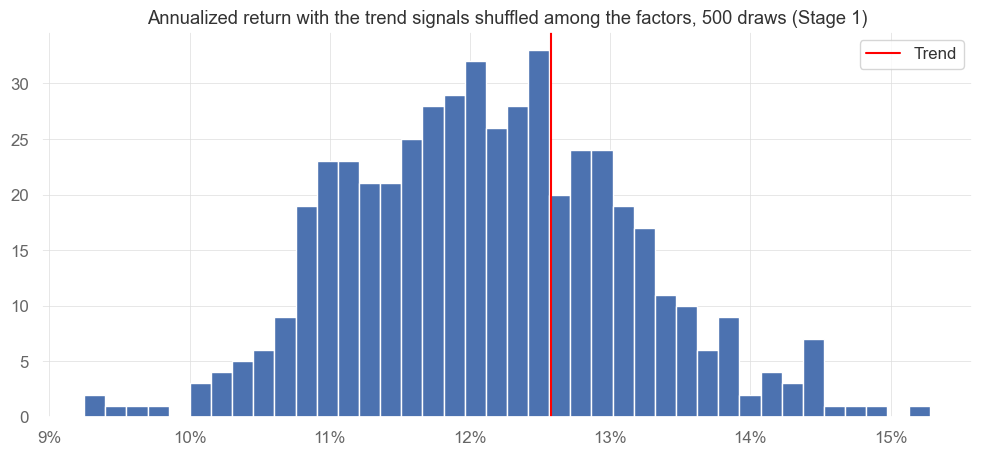

In [40]:
rng = np.random.default_rng(42)

shuffled_returns = []
for draw in tqdm(range(500)):
    W = dict()
    for dt in trade_dates:
        s = monthly_signal.loc[dt].dropna()
        W[dt] = trend_weights(pd.Series(rng.permutation(s.values), index = s.index))
    shuffled_returns.append(statistics(factor_series_return(pd.DataFrame(W).T.reindex(index = trade_dates, columns = trend_factors).fillna(0)))['Annualized Return'])
shuffled_returns = np.array(shuffled_returns)

trend_return = statistics(stage1_returns['Trend'])['Annualized Return']
print(f'Shuffled signals: mean {shuffled_returns.mean():.1%}, 5th percentile {np.percentile(shuffled_returns, 5):.1%}, 95th percentile {np.percentile(shuffled_returns, 95):.1%}, maximum {shuffled_returns.max():.1%}')
print(f'Trend: {trend_return:.1%}, above {np.mean(shuffled_returns < trend_return):.0%} of the draws')

plt.figure(figsize = (12, 5))
plt.hist(shuffled_returns, bins = 40)
plt.axvline(trend_return, color = 'red', label = 'Trend')
plt.title('Annualized return with the trend signals shuffled among the factors, 500 draws (Stage 1)')
plt.gca().xaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals = 0))
plt.legend()
plt.grid(True)

# Conclusions

- Applied to single stocks, the trend index does better than applied to factors. Rebalanced every day, the 20 stocks with the strongest trend return 19.4% a year from February 2010, with a Sharpe ratio of 0.53 and a NEFIN alpha of 0.62% per month (t-statistic of 3.0), but they replace about one stock a day, a turnover of about 106% per month, so transaction costs would take a large part of that return. Rebalanced every month, like the other strategies of the repository, the same portfolio returns 15.7% a year (Sharpe ratio of 0.36) and replaces about 46% of its stocks per month, and the top quintile returns 16.4%. The factor basket below turns over 29% per month.
- A long-only basket of the six factors works: it returns 12.6% a year with the trend weights and 12.2% with equal weights, against 6.1% for the Ibovespa and 9.9% for the CDI, with a significant NEFIN alpha in both cases.
- The trend adds little over equal weights. The equal-weighted basket has a higher alpha (0.40% per month, t-statistic of 3.1, against 0.32% and 2.2) and a lower turnover (18% of the portfolio per month, against 29%). With the signals shuffled among the factors, the trend weights still return 12.1% on average, and the strategy beats only 68% of the draws. Most of the gain over the earlier versions came from leaving out Size, Reversal and the Magic Formula, which were the weakest factors, and not from the timing of the trend.
- The trend helped in some years, such as 2015 and 2020, and hurt in others, such as 2023 to 2025. The result barely changes when the signal is lagged by up to 21 days.
- The trend weights hold about five of the six factors in a typical month. The Low Risk composite has the largest average weight, about a quarter of the portfolio. In 18 of the 198 rebalances no factor had a positive trend, and the portfolio held all of them with equal weights.
- The trend basket holds about 69 stocks, with an effective N of about 52 and a largest weight of about 4%. At the start of the sample the fundamental factors cover few stocks: in February 2010 the Leverage leg held a single stock, which then had half of the equal-weighted basket.
- The basket moves with the equal-weighted universe (R² of 0.88), which is also why its shape looks like the Combination's. Over the same window, the Combination of `05_` does better, with 15.7% a year. Both are in sample: the factors of the Combination were chosen after the screening of `04_`, and the six factors here were chosen after the tests of this notebook's earlier versions.